<a href="https://colab.research.google.com/github/evcgitorg/UCG-Paradigmas/blob/main/Villalta_Enrique_Taller3_PipelineML.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#0. Enlace del notebook
https://colab.research.google.com/drive/1-oHUF4P6fS_2DkvVRrVIeOa3w1wRuaPG?usp=sharing


# 1. Contexto del Dataset
## USA House Prices - Precios de casa en USA | Regresión de `price` - precio de la casa
### Enlace: https://www.kaggle.com/datasets/fratzcan/usa-house-prices
El dataset seleccionado corresponde a información sobre precios de casas, el propósito es examinar el comportamiento del precio de la vivienda -variable objetivo- `price` considerando las especificaciones de las mismas, se construirá modelos de regresión, árbol de regresión y Random Forest Regressor; además se realizará comparartiva de los resultados de los tres modelos.
El dataset contiene 4140 filas y 18 columnas, a continuación el detalle:
* date: Fecha en que se vendió la propiedad
* price: precio de la a vivienda
* bedrooms: número de dormitorios por propiedad
* bathrooms: número de baños por propiedad
* sqft_living: tamaño de la zona habitable en pies cuadrados
* sqft_lot: tamaño del terreno en pies cuadrados
* floors: el número de plantas de la propiedad
* waterfront: indicador binario (1 si la propiedad tiene vista al mar, 0 no tiene)
* view: un índice de 0 a 4 que indique la calidad de la vista de la propiedad
* condition: índice del 1 al 5 que evalúa el estado de la propiedad
* sqft_above: pies cuadrados de la propiedad sobre el sótano
* sqft_basement: pies cuadrados del sótano
* yr_built: año de construcción de la propiedad
* yr_renovated: año de la última renovación de la propiedad
* street: dirección de la propiedad
* city: ciudad donde se encuentra la propiedad
* statezip: el estado y zip code de la propiedad
* country: ciudad


#2. Carga y exploración inicial
Lectura del archivo, revisión de dimensiones, tipos de datos, valores faltantes y primeras observaciones.

## Importar librerias y configuración de entorno

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
pd.set_option("display.max_columns", 30)
pd.set_option('display.float_format', lambda x: '%.2f' % x if isinstance(x, (float, np.float64)) else '%d' % x)
np.random.seed(42)

## Lectura del archivo y revisión de dimensiones

In [ ]:
ruta = "/content/USA Housing Dataset.csv"
df = pd.read_csv(ruta)
df

,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,sqft_above,sqft_basement,yr_built,yr_renovated,street,city,statezip,country
0,2014-05-09 00:00:00,376000.00,3.00,2.00,1340,1384,3.00,0,0,3,1340,0,2008,0,9245-9249 Fremont Ave N,Seattle,WA 98103,USA
1,2014-05-09 00:00:00,800000.00,4.00,3.25,3540,159430,2.00,0,0,3,3540,0,2007,0,33001 NE 24th St,Carnation,WA 98014,USA
2,2014-05-09 00:00:00,2238888.00,5.00,6.50,7270,130017,2.00,0,0,3,6420,850,2010,0,7070 270th Pl SE,Issaquah,WA 98029,USA
3,2014-05-09 00:00:00,324000.00,3.00,2.25,998,904,2.00,0,0,3,798,200,2007,0,820 NW 95th St,Seattle,WA 98117,USA
4,2014-05-10 00:00:00,549900.00,5.00,2.75,3060,7015,1.00,0,0,5,1600,1460,1979,0,10834 31st Ave SW,Seattle,WA 98146,USA
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4135,2014-07-09 00:00:00,308166.67,3.00,1.75,1510,6360,1.00,0,0,4,1510,0,1954,1979,501 N 143rd St,Seattle,WA 98133,USA
4136,2014-07-09 00:00:00,534333.33,3.00,2.50,1460,7573,2.00,0,0,3,1460,0,1983,2009,14855 SE 10th Pl,Bellevue,WA 98007,USA
4137,2014-07-09 00:00:00,416904.17,3.00,2.50,3010,7014,2.00,0,0,3,3010,0,2009,0,759 Ilwaco Pl NE,Renton,WA 98059,USA
4138,2014-07-10 00:00:00,203400.00,4.00,2.00,2090,6630,1.00,0,0,3,1070,1020,1974,0,5148 S Creston St,Seattle,WA 98178,USA


In [ ]:
# Convertir columna ´date´ a formato datetime
# df['date'] = pd.to_datetime(df['date'])

## Tipos de datos

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4140 entries, 0 to 4139
Data columns (total 18 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   date           4140 non-null   object 
 1   price          4140 non-null   float64
 2   bedrooms       4140 non-null   float64
 3   bathrooms      4140 non-null   float64
 4   sqft_living    4140 non-null   int64  
 5   sqft_lot       4140 non-null   int64  
 6   floors         4140 non-null   float64
 7   waterfront     4140 non-null   int64  
 8   view           4140 non-null   int64  
 9   condition      4140 non-null   int64  
 10  sqft_above     4140 non-null   int64  
 11  sqft_basement  4140 non-null   int64  
 12  yr_built       4140 non-null   int64  
 13  yr_renovated   4140 non-null   int64  
 14  street         4140 non-null   object 
 15  city           4140 non-null   object 
 16  statezip       4140 non-null   object 
 17  country        4140 non-null   object 
dtypes: float

## Resumen estadístico variables numéricas

In [ ]:
df.describe()

,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,sqft_above,sqft_basement,yr_built,yr_renovated
count,4140.00,4140.00,4140.00,4140.00,4140.00,4140.00,4140.00,4140.00,4140.00,4140.00,4140.00,4140.00,4140.00
mean,553062.88,3.40,2.16,2143.64,14697.64,1.51,0.01,0.25,3.45,1831.35,312.29,1970.81,808.37
std,583686.45,0.90,0.78,957.48,35876.84,0.53,0.09,0.79,0.68,861.38,464.35,29.81,979.38
min,0.00,0.00,0.00,370.00,638.00,1.00,0.00,0.00,1.00,370.00,0.00,1900.00,0.00
25%,320000.00,3.00,1.75,1470.00,5000.00,1.00,0.00,0.00,3.00,1190.00,0.00,1951.00,0.00
50%,460000.00,3.00,2.25,1980.00,7676.00,1.50,0.00,0.00,3.00,1600.00,0.00,1976.00,0.00
75%,659125.00,4.00,2.50,2620.00,11000.00,2.00,0.00,0.00,4.00,2310.00,602.50,1997.00,1999.00
max,26590000.00,8.00,6.75,10040.00,1074218.00,3.50,1.00,4.00,5.00,8020.00,4820.00,2014.00,2014.00


## Resumen estadístico variables categóricas

In [ ]:
# Intentar describir variables categóricas si existen en el DataFrame
columnas_objeto = df.select_dtypes(include='object').columns
if len(columnas_objeto) > 0:
    display(df.describe(include="object"))
else:
    print("No hay columnas de tipo 'object' (categóricas) en el DataFrame para describir.")

,date,street,city,statezip,country
count,4140,4140,4140,4140,4140
unique,68,4079,43,77,1
top,2014-06-23 00:00:00,2520 Mulberry Walk NE,Seattle,WA 98103,USA
freq,142,4,1415,128,4140


**Lectura inicial:** `price`  COMPLETAR

## Verificación de datos duplicados, nulos y su porcentaje

In [ ]:
nulos = df.isna().sum()
display(pd.DataFrame({"Nulos": nulos, "Porcentaje (%)": (100*nulos/len(df)).round(2)}))
print("Filas duplicadas:", df.duplicated().sum())

,Nulos,Porcentaje (%)
date,0,0.00
price,0,0.00
bedrooms,0,0.00
bathrooms,0,0.00
sqft_living,0,0.00
sqft_lot,0,0.00
floors,0,0.00
waterfront,0,0.00
view,0,0.00
condition,0,0.00


Filas duplicadas: 0


## Gráfico mapa de calor para mostrar los datos faltantes antes de la limpieza de los datos

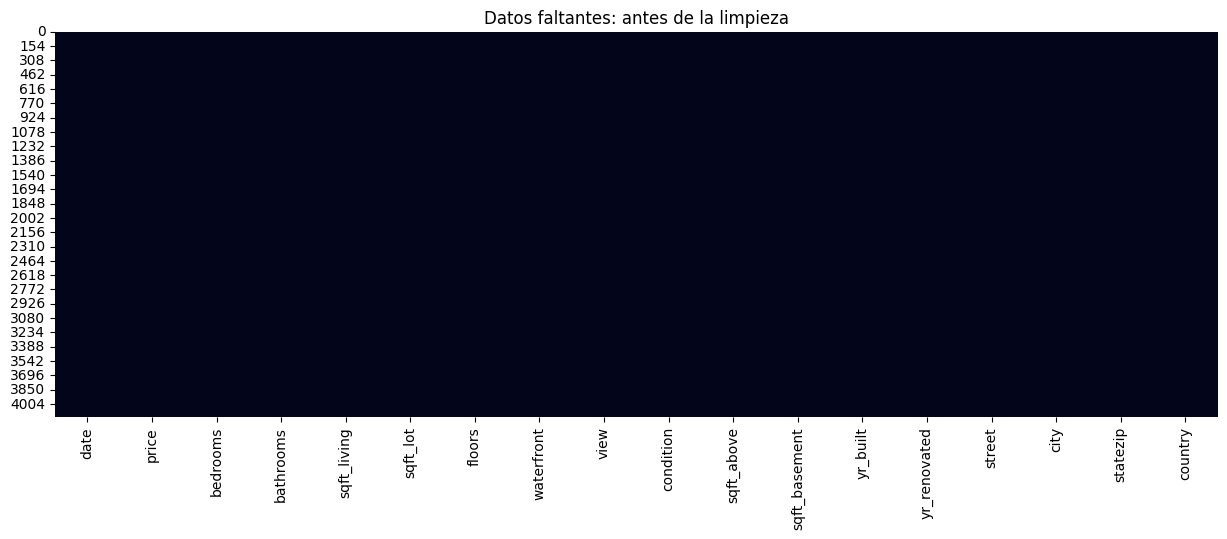

In [ ]:
plt.figure(figsize=(15, 5))
sns.heatmap(df.isna(), cbar=False)
plt.title("Datos faltantes: antes de la limpieza")
plt.show()

## Limpieza de datos: Elimina filas con valores faltantes o nulos, además, elimina filas duplicadas; genera nuevo dataset

In [ ]:
df_copia = df.dropna().drop_duplicates().copy()
print("Antes:", len(df), "| Después:", len(df_copia))

Antes: 4140 | Después: 4140


## Gráfico mapa de calor para mostrar los datos después de la limpieza de los datos

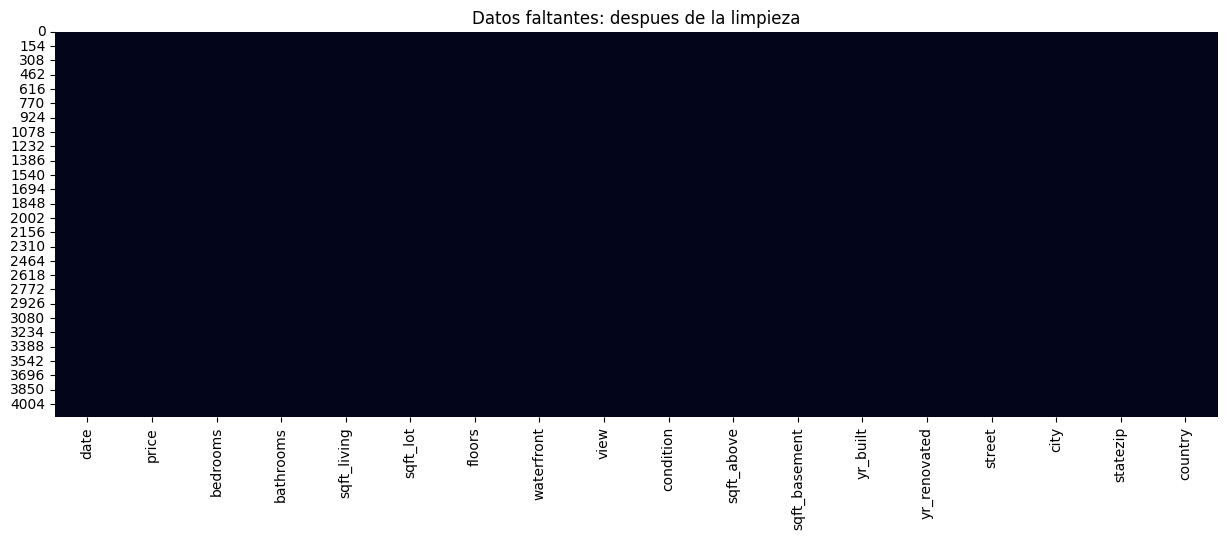

In [ ]:
plt.figure(figsize=(15, 5))
sns.heatmap(df_copia.isna(), cbar=False)
plt.title("Datos faltantes: despues de la limpieza")
plt.show()

## Exploración de valores extremos mediante diagramas de caja e IQR (rango intercuartílico)

In [ ]:
numericas = df_copia.select_dtypes(include="number").columns.tolist()
px.box(df_copia, y=numericas, points="outliers", title="Distribuciones numéricas: inspección de extremos").show()

In [ ]:
px.box(df_copia, y="price", points="outliers", title="Precio: posible presencia de valores extremos").show()

In [ ]:
q1, q3 = df_copia["price"].quantile([0.25, 0.75]) # obtengo los cuartiles 1 y 3
iqr = q3 - q1 # calcula el rango intercuartílico
limite_inferior, limite_superior = q1 - 1.5*iqr, q3 + 1.5*iqr # calcula los limites inferior y superior para identificar los valores extremos
extremos = df_copia[(df_copia["price"] < limite_inferior) | (df_copia["price"] > limite_superior)]
print("Límites IQR:  inferior ", round(limite_inferior,2)," superior ", round(limite_superior,2), "| Registros identificados:", len(extremos))
display(extremos.head(10))

Límites IQR:  inferior  -188687.5  superior  1167812.5 | Registros identificados: 215


,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,sqft_above,sqft_basement,yr_built,yr_renovated,street,city,statezip,country
2,2014-05-09 00:00:00,2238888.00,5.00,6.50,7270,130017,2.00,0,0,3,6420,850,2010,0,7070 270th Pl SE,Issaquah,WA 98029,USA
11,2014-05-12 00:00:00,1225000.00,4.00,4.50,5420,101930,1.00,0,0,3,3890,1530,2001,0,25005 NE Patterson Way,Redmond,WA 98053,USA
18,2014-05-12 00:00:00,1200000.00,3.00,1.75,1560,8078,1.50,1,4,4,1560,0,1928,0,3603 W Mercer Way,Mercer Island,WA 98040,USA
22,2014-05-12 00:00:00,1575000.00,5.00,2.75,3650,20150,1.00,0,0,4,2360,1290,1975,0,1216 86th Ave NE,Bellevue,WA 98004,USA
28,2014-05-12 00:00:00,1315000.00,4.00,3.50,3460,3997,2.00,0,0,3,2560,900,2004,2003,2346 N 59th St,Seattle,WA 98103,USA
64,2014-05-12 00:00:00,1300000.00,4.00,3.25,2330,9687,2.00,0,3,3,2330,0,1918,0,731 McGilvra Blvd E,Seattle,WA 98112,USA
65,2014-05-12 00:00:00,1346400.00,5.00,1.75,3380,20021,1.00,0,0,4,1690,1690,1963,0,9640 NE 32nd St,Clyde Hill,WA 98004,USA
74,2014-05-12 00:00:00,1225000.00,4.00,2.25,3070,16028,1.00,0,3,3,1870,1200,1976,0,8434 W Mercer Way,Mercer Island,WA 98040,USA
77,2014-05-12 00:00:00,1264000.00,4.00,3.75,3490,9170,2.00,0,0,3,3490,0,2012,1912,10442 SE 13th St,Bellevue,WA 98004,USA
104,2014-05-13 00:00:00,1895000.00,5.00,2.25,3120,16672,2.00,0,0,4,3120,0,1969,0,9045 NE 40th Pl,Yarrow Point,WA 98004,USA


## Elimino outliers del dataset, uso los valores de `limite_inferior` y `limite_superior` sobre la columna precio - price

In [ ]:
df_limpio = df_copia[
    (df_copia['price'] >= limite_inferior) & (df_copia['price'] <= limite_superior)
]

In [ ]:
print("Antes:", len(df_copia), "| Después:", len(df_limpio))

Antes: 4140 | Después: 3925


# 3. Análisis exploratorio (EDA)
Estadística descriptiva, distribución de variables, análisis de la variable objetivo y visualizaciones relevantes.

In [ ]:
# Resumen estadístico de variables numéricas
numericas = df_limpio.select_dtypes(include="number").columns.tolist()
categoricas = df_limpio.select_dtypes(include="object").columns.tolist()
display(df_limpio[numericas].describe())

,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,sqft_above,sqft_basement,yr_built,yr_renovated
count,3925.00,3925.00,3925.00,3925.00,3925.00,3925.00,3925.00,3925.00,3925.00,3925.00,3925.00,3925.00,3925.00
mean,482070.79,3.36,2.10,2045.51,14483.22,1.50,0.00,0.19,3.45,1758.58,286.93,1970.84,810.47
std,223340.10,0.89,0.73,829.35,36264.43,0.53,0.07,0.68,0.67,779.24,428.06,29.59,979.79
min,0.00,0.00,0.00,370.00,638.00,1.00,0.00,0.00,1.00,370.00,0.00,1900.00,0.00
25%,314500.00,3.00,1.75,1440.00,5000.00,1.00,0.00,0.00,3.00,1170.00,0.00,1951.00,0.00
50%,445000.00,3.00,2.25,1930.00,7563.00,1.50,0.00,0.00,3.00,1550.00,0.00,1975.00,0.00
75%,615000.00,4.00,2.50,2530.00,10688.00,2.00,0.00,0.00,4.00,2210.00,570.00,1997.00,1999.00
max,1165000.00,8.00,6.25,8020.00,1074218.00,3.50,1.00,4.00,5.00,8020.00,2300.00,2014.00,2014.00


In [ ]:
# Número de casas por variables categoricas
for columna in categoricas:
    print("\n", columna)
    display(df_copia[columna].value_counts().to_frame("Casas").head(20))


 date


,Casas
date,
2014-06-23 00:00:00,142
2014-06-25 00:00:00,131
2014-06-26 00:00:00,131
2014-07-08 00:00:00,127
2014-07-09 00:00:00,121
2014-06-24 00:00:00,120
2014-05-20 00:00:00,116
2014-07-01 00:00:00,116
2014-06-17 00:00:00,113



 street


,Casas
street,
2520 Mulberry Walk NE,4
2500 Mulberry Walk NE,3
22840 SE 269th St,2
6520-6588 8th Ave NW,2
3510 S Holly St,2
2803 SW Bataan St,2
769 N 74th St,2
21132 NE 42nd St,2
Indian Trail,2



 city


,Casas
city,
Seattle,1415
Renton,261
Bellevue,260
Redmond,209
Kent,167
Kirkland,166
Issaquah,162
Auburn,162
Sammamish,158



 statezip


,Casas
statezip,
WA 98103,128
WA 98052,120
WA 98117,119
WA 98115,114
WA 98006,101
WA 98059,94
WA 98038,90
WA 98074,89
WA 98042,88



 country


,Casas
country,
USA,4140


In [ ]:
# Distribución de precios de casas
fig = px.histogram(df_limpio, x="price", nbins=10, marginal="box", title="Distribución de precios de casas")
# Configuro el eje X: iniciar en 0, saltos cada 100,000 - valores en dólares
fig.update_xaxes(
    tick0=0,
    dtick=100000
)
fig.show()

In [ ]:
# Revisar frecuencia de casas por vista de la calidad de la propiedad - variable condition
px.bar(df_limpio["condition"].value_counts().rename_axis("Condición propiedad").reset_index(name="Casas"),
       x="Condición propiedad", y="Casas", title="Frecuencia por condición de la propiedad").show()

In [ ]:
# Precio promedio por condición de la propiedad - variable condition
resumen = df_limpio.groupby("condition", as_index=False).agg(Precio_promedio=("price","mean"), Casas=("price","size"))
display(resumen.sort_values("Precio_promedio", ascending=False))

,condition,Precio_promedio,Casas
4,5,533089.63,365
2,3,485897.11,2462
3,4,462428.98,1067
0,1,316960.00,5
1,2,241344.62,26


In [ ]:
px.bar(resumen.sort_values("Precio_promedio", ascending=False), x="condition", y="Precio_promedio",
       title="Precio promedio por condición (descriptivo)").show()

In [ ]:
px.box(df_limpio, x="bedrooms", y="price", color="bedrooms",
       title="Precio según número de dormitorios").show()

In [ ]:
# Precio promedio por número de baños - variable bedrooms
resumen = df_limpio.groupby("bedrooms", as_index=False).agg(Precio_promedio=("price","mean"), Casas=("price","size"))
display(resumen.sort_values("Precio_promedio", ascending=False))

,bedrooms,Precio_promedio,Casas
0,0.00,1095000.00,1
7,7.00,609111.11,9
6,6.00,581469.57,46
5,5.00,557486.87,269
4,4.00,555847.93,1271
3,3.00,447241.52,1794
2,2.00,381288.50,497
8,8.00,340000.00,1
1,1.00,274727.03,37


In [ ]:
px.box(df_limpio, x="bathrooms", y="price", color="bathrooms",
       title="Precio según número de baños").show()

In [ ]:
# Precio promedio por número de baños - variable bathrooms
resumen = df_limpio.groupby("bathrooms", as_index=False).agg(Precio_promedio=("price","mean"), Casas=("price","size"))
display(resumen.sort_values("Precio_promedio", ascending=True))

,bathrooms,Precio_promedio,Casas
21,6.25,0.00,1
1,0.75,293955.94,17
19,5.25,300000.00,1
2,1.00,325209.42,674
4,1.50,403421.95,259
5,1.75,445956.13,547
6,2.00,453008.74,371
7,2.25,495719.79,365
3,1.25,530750.00,2
8,2.50,531725.28,1030


In [ ]:
# Relación el precio de casas con la ciudad
px.scatter(df_limpio, x="city", y="price", color="sqft_lot", hover_data=["bedrooms", "bathrooms", "sqft_living"],
           opacity=0.65, title="Ciudad vs. precio · color por ciudad").show()

In [ ]:
px.scatter(df_limpio, x="condition", y="price", color="sqft_lot", hover_data=["bedrooms", "bathrooms", "sqft_living"],
           opacity=0.65, title="Ciudad vs. precio · color por ciudad").show()

###Gráfico de correlaciones

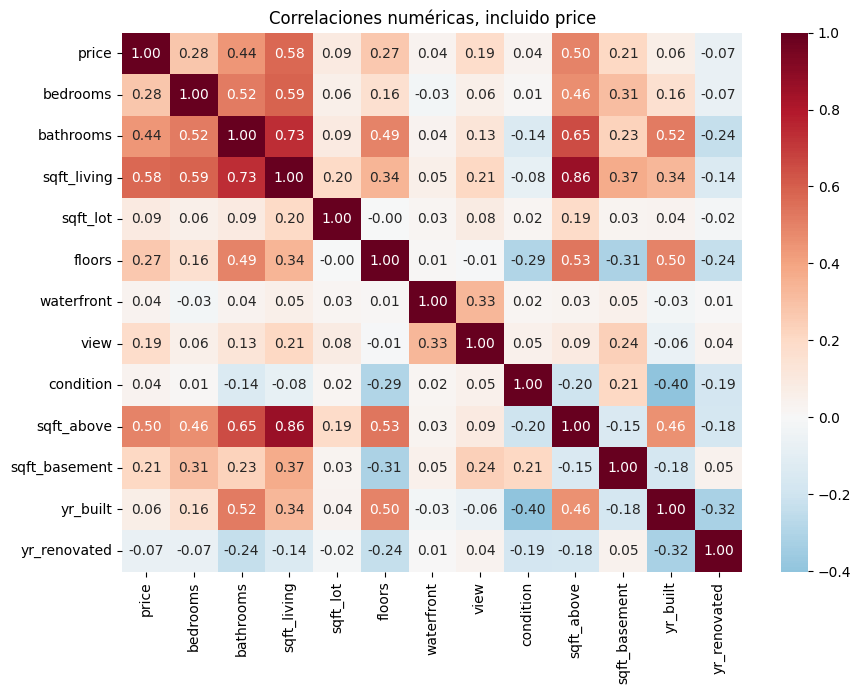

In [ ]:
correlaciones = df_limpio[numericas].corr()
plt.figure(figsize=(10, 7))
sns.heatmap(correlaciones, annot=True, fmt=".2f", cmap="RdBu_r", center=0)
plt.title("Correlaciones numéricas, incluido price")
plt.show()

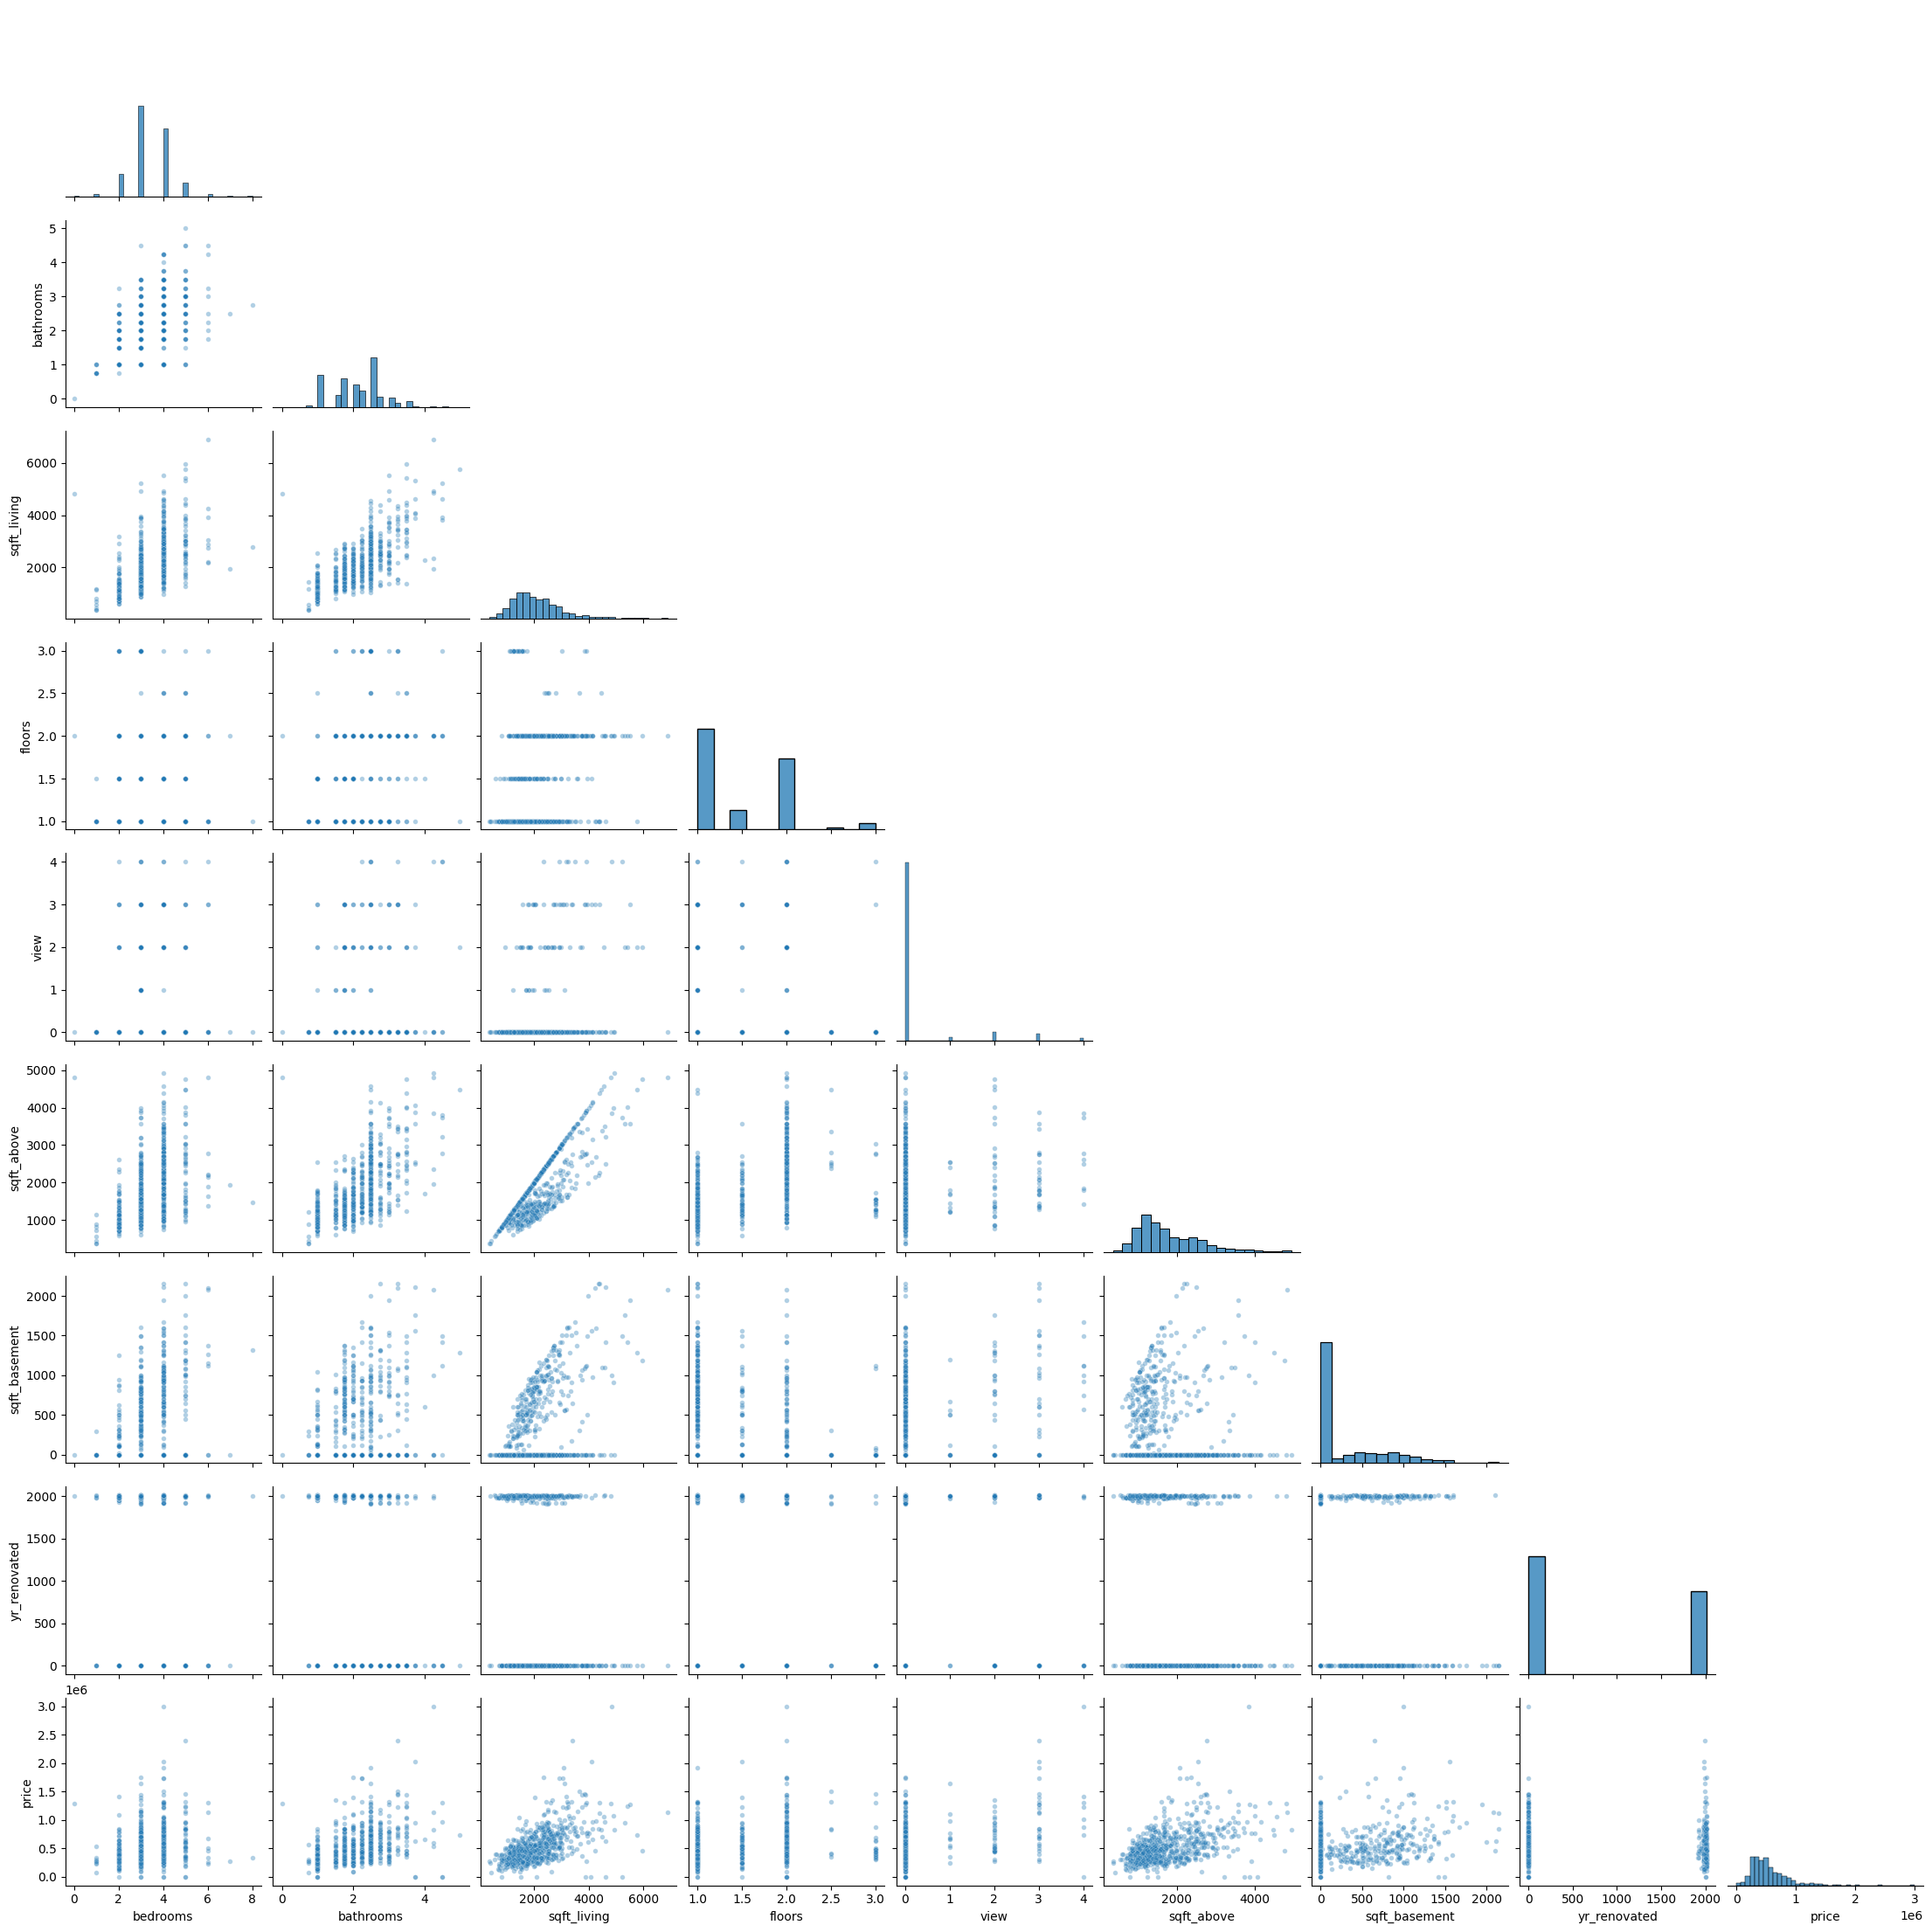

In [ ]:
columnas_pair = ["bedrooms", "bathrooms", "sqft_living","floors","view", "sqft_above", "sqft_basement","yr_renovated", "price"]
muestra_pair = df_copia[columnas_pair].sample(n=min(700, len(df_copia)), random_state=42)
sns.pairplot(muestra_pair, vars=columnas_pair, corner=True, plot_kws={"alpha":0.35, "s":16})
plt.show()

# 4. Preparación de datos

In [ ]:
X = df_limpio.drop(columns="price")
y = df_limpio["price"].astype(float)
X.head()

,date,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,sqft_above,sqft_basement,yr_built,yr_renovated,street,city,statezip,country
0,2014-05-09 00:00:00,3.00,2.00,1340,1384,3.00,0,0,3,1340,0,2008,0,9245-9249 Fremont Ave N,Seattle,WA 98103,USA
1,2014-05-09 00:00:00,4.00,3.25,3540,159430,2.00,0,0,3,3540,0,2007,0,33001 NE 24th St,Carnation,WA 98014,USA
3,2014-05-09 00:00:00,3.00,2.25,998,904,2.00,0,0,3,798,200,2007,0,820 NW 95th St,Seattle,WA 98117,USA
4,2014-05-10 00:00:00,5.00,2.75,3060,7015,1.00,0,0,5,1600,1460,1979,0,10834 31st Ave SW,Seattle,WA 98146,USA
5,2014-05-10 00:00:00,3.00,2.50,2130,6969,2.00,0,0,3,2130,0,2003,0,Cedar to Green River Trail,Maple Valley,WA 98038,USA


In [ ]:
display(y.describe())

,price
count,3925.00
mean,482070.79
std,223340.10
min,0.00
25%,314500.00
50%,445000.00
75%,615000.00
max,1165000.00


**One-hot encoding** representa categorías nominales sin introducir un orden ficticio; `StandardScaler` escala las columnas numéricas. El ajuste se realiza solo en entrenamiento.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)
print("Entrenamiento:", X_train.shape, "| Prueba:", X_test.shape)

Entrenamiento: (3140, 17) | Prueba: (785, 17)


In [ ]:
columnas_num = X.select_dtypes(include="number").columns.tolist()
columnas_cat = X.select_dtypes(include="object").columns.tolist()
preprocesador = ColumnTransformer([
    ("numeros", StandardScaler(), columnas_num),
    ("categorias", OneHotEncoder(handle_unknown="ignore", sparse_output=False), columnas_cat)
])
print("Numéricas:", columnas_num, "| Categóricas:", columnas_cat)

Numéricas: ['bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 'floors', 'waterfront', 'view', 'condition', 'sqft_above', 'sqft_basement', 'yr_built', 'yr_renovated'] | Categóricas: ['date', 'street', 'city', 'statezip', 'country']


In [ ]:
display(X_train.head())

,date,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,sqft_above,sqft_basement,yr_built,yr_renovated,street,city,statezip,country
918,2014-05-27 00:00:00,2.00,2.50,2160,5581,1.00,0,0,3,2160,0,2002,0,23744 NE 116th Pl,Redmond,WA 98053,USA
1130,2014-05-29 00:00:00,3.00,2.50,2930,6050,2.00,0,0,3,2930,0,2008,0,34303 Elm Ave SE,Snoqualmie,WA 98065,USA
3898,2014-05-06 00:00:00,5.00,3.50,3480,36615,2.00,0,0,4,2490,990,1983,0,21809 SE 38th Pl,Issaquah,WA 98075,USA
3827,2014-07-10 00:00:00,6.00,2.75,2980,5000,1.50,0,0,3,2480,500,1916,1986,5428 Kirkwood Pl N,Seattle,WA 98103,USA
1205,2014-06-02 00:00:00,3.00,1.50,2030,8880,1.00,0,0,3,1330,700,1963,2008,4915 17th Ave S,Seattle,WA 98108,USA


In [ ]:
X_train_listo = preprocesador.fit_transform(X_train)
X_test_listo = preprocesador.transform(X_test)
nombres = preprocesador.get_feature_names_out()
display(pd.DataFrame(X_train_listo, columns=nombres, index=X_train.index).head())

,numeros__bedrooms,numeros__bathrooms,numeros__sqft_living,numeros__sqft_lot,numeros__floors,numeros__waterfront,numeros__view,numeros__condition,numeros__sqft_above,numeros__sqft_basement,numeros__yr_built,numeros__yr_renovated,categorias__date_2014-05-02 00:00:00,categorias__date_2014-05-05 00:00:00,categorias__date_2014-05-06 00:00:00,...,categorias__statezip_WA 98136,categorias__statezip_WA 98144,categorias__statezip_WA 98146,categorias__statezip_WA 98148,categorias__statezip_WA 98155,categorias__statezip_WA 98166,categorias__statezip_WA 98168,categorias__statezip_WA 98177,categorias__statezip_WA 98178,categorias__statezip_WA 98188,categorias__statezip_WA 98198,categorias__statezip_WA 98199,categorias__statezip_WA 98288,categorias__statezip_WA 98354,categorias__country_USA
918,-1.53,0.54,0.14,-0.24,-0.93,-0.07,-0.27,-0.68,0.52,-0.67,1.06,-0.82,0.00,0.00,0.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1.00
1130,-0.42,0.54,1.08,-0.23,0.94,-0.07,-0.27,-0.68,1.52,-0.67,1.26,-0.82,0.00,0.00,0.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1.00
3898,1.82,1.91,1.74,0.57,0.94,-0.07,-0.27,0.80,0.95,1.63,0.41,-0.82,0.00,0.00,1.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1.00
3827,2.93,0.88,1.14,-0.26,0.01,-0.07,-0.27,-0.68,0.94,0.49,-1.86,1.22,0.00,0.00,0.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1.00
1205,-0.42,-0.83,-0.02,-0.16,-0.93,-0.07,-0.27,-0.68,-0.56,0.96,-0.26,1.24,0.00,0.00,0.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1.00


In [ ]:
print("Antes:", X_train.shape, "| Después:", X_train_listo.shape)
print("Prueba transformada:", X_test_listo.shape)

Antes: (3140, 17) | Después: (3140, 3300)
Prueba transformada: (785, 3300)


**Nota:** `fit_transform` aprende las reglas en `X_train`; `transform` las aplica a `X_test` sin recalcularlas.

# 5. Modelo con Scikit-learn

Probamos regresión lineal, árbol de regresión y Random Forest Regressor;  utilizamos **MAE, RMSE y R²** para la métricas

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn import set_config
set_config(display="diagram")
def evaluar(real, predicho):
    return {"MAE": mean_absolute_error(real, predicho),
            "RMSE": np.sqrt(mean_squared_error(real, predicho)),
            "R2": r2_score(real, predicho)}

##**Regresión Lineal**

In [ ]:
modelo_lineal = Pipeline([("preparacion", preprocesador), ("modelo", LinearRegression())])
modelo_lineal.fit(X_train, y_train)
modelo_lineal

Pipeline(steps=[('preparacion',
                 ColumnTransformer(transformers=[('numeros', StandardScaler(),
                                                  ['bedrooms', 'bathrooms',
                                                   'sqft_living', 'sqft_lot',
                                                   'floors', 'waterfront',
                                                   'view', 'condition',
                                                   'sqft_above',
                                                   'sqft_basement', 'yr_built',
                                                   'yr_renovated']),
                                                 ('categorias',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                sparse_output=False),
                                                  ['date', 'street', 'city',
                                                   'statezip', 'country'])])),
                ('modelo', LinearRegression())])

In [ ]:
pred_lineal = modelo_lineal.predict(X_test)
print(evaluar(y_test, pred_lineal))

{'MAE': 100224.9989702096, 'RMSE': np.float64(153966.25843732833), 'R2': 0.5211088276733183}


##**Árbol de regresión**

In [ ]:
modelo_arbol = Pipeline([("preparacion", preprocesador),
                         ("modelo", DecisionTreeRegressor(max_depth=8, min_samples_leaf=5, random_state=42))])
modelo_arbol.fit(X_train, y_train)
modelo_arbol

Pipeline(steps=[('preparacion',
                 ColumnTransformer(transformers=[('numeros', StandardScaler(),
                                                  ['bedrooms', 'bathrooms',
                                                   'sqft_living', 'sqft_lot',
                                                   'floors', 'waterfront',
                                                   'view', 'condition',
                                                   'sqft_above',
                                                   'sqft_basement', 'yr_built',
                                                   'yr_renovated']),
                                                 ('categorias',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                sparse_output=False),
                                                  ['date', 'street', 'city',
                                                   'statezip', 'country'])])),
                ('modelo',
                 DecisionTreeRegressor(max_depth=8, min_samples_leaf=5,
                                       random_state=42))])

In [ ]:
pred_arbol = modelo_arbol.predict(X_test)
print(evaluar(y_test, pred_arbol))

{'MAE': 115042.89114913995, 'RMSE': np.float64(162634.4652119433), 'R2': 0.465668359989013}


##**Random Forest Regressor**

In [ ]:
modelo_rf = Pipeline([("preparacion", preprocesador),
                      ("modelo", RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1))])
modelo_rf.fit(X_train, y_train)
modelo_rf

Pipeline(steps=[('preparacion',
                 ColumnTransformer(transformers=[('numeros', StandardScaler(),
                                                  ['bedrooms', 'bathrooms',
                                                   'sqft_living', 'sqft_lot',
                                                   'floors', 'waterfront',
                                                   'view', 'condition',
                                                   'sqft_above',
                                                   'sqft_basement', 'yr_built',
                                                   'yr_renovated']),
                                                 ('categorias',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                sparse_output=False),
                                                  ['date', 'street', 'city',
                                                   'statezip', 'country'])])),
                ('modelo', RandomForestRegressor(n_jobs=-1, random_state=42))])

In [ ]:
pred_rf = modelo_rf.predict(X_test)
print(evaluar(y_test, pred_rf))

{'MAE': 86406.30686502176, 'RMSE': np.float64(136941.5729672434), 'R2': 0.621159550229493}


##Predicción por registros y errores

In [ ]:
comparacion = pd.DataFrame({"Real": y_test.to_numpy(), "Regresión lineal":pred_lineal,
                            "Árbol":pred_arbol, "Random Forest":pred_rf}, index=y_test.index)
comparacion["Error_RF"] = comparacion["Real"]-comparacion["Random Forest"]
display(comparacion.head(20))

,Real,Regresión lineal,Árbol,Random Forest,Error_RF
3670,530000.00,758612.98,798111.11,901621.30,-371621.30
486,243000.00,173249.88,183642.86,344266.02,-101266.02
4070,362750.00,655208.73,424286.24,494753.88,-132003.88
3802,625000.00,500438.01,719187.66,496219.40,128780.60
2199,1010000.00,861807.38,611500.37,631118.62,378881.38
4057,309000.00,314922.89,551207.48,422773.63,-113773.63
690,926300.00,615041.53,594078.83,720390.63,205909.37
874,375000.00,320309.90,504250.01,415529.86,-40529.86
4033,300000.00,537450.07,551207.48,470186.13,-170186.13
3945,0.00,781324.93,807870.43,892365.88,-892365.88


In [ ]:
px.scatter(comparacion, x="Real", y="Random Forest", hover_data=["Error_RF"],
           title="Random Forest: promedio real vs. estimado").add_shape(
               type="line", x0=y_test.min(),y0=y_test.min(),x1=y_test.max(),y1=y_test.max(),
               line=dict(dash="dash",color="gray")).show()

#**Interpretación**
Al ejecutar los tres modelos sobre el dataset observo que R2 mejora utilizando **Random Forest Regressor** , pero aún no se logra R2 por encima de 80%, se han eliminado los outliers de la columna `price` no se aprecia una alimeación entre precio estimado y real.

# 6. Modelo con TensorFlow/Keras

 La red tendrá entradas codificadas → 16 neuronas ReLU → 1 salida lineal. Una salida lineal produce una estimación de precio, no una probabilidad. Para facilitar el aprendizaje escalaremos únicamente el precio de entrenamiento y recuperaremos USD en la evaluación. Las métricas definitivas siempre se calcularán sobre precios en USD.

In [ ]:

import tensorflow as tf  # Biblioteca para construir y entrenar redes neuronales.
from tensorflow.keras import Sequential  # Red de capas consecutivas.
from tensorflow.keras.layers import Dense  # Capas de neuronas conectadas.
from tensorflow.keras.utils import plot_model  # Dibuja las capas y sus formas.

tf.keras.utils.set_random_seed(42)  # Ayuda a obtener resultados reproducibles.

Preparar matrices para TensorFlow

In [ ]:
X_train_tf = X_train_listo.astype("float32")  # Variables predictoras de entrenamiento.
X_test_tf = X_test_listo.astype("float32")  # Variables predictoras de prueba.

print("X_train:", X_train_tf.shape)  # Filas y columnas que recibirá la red.
print("X_test:", X_test_tf.shape)  # Mismas columnas, pero valore de casa nuevos.
display(pd.DataFrame(X_train_tf[:5], columns=nombres))  # Cinco ejemplos de entrada.

X_train: (3140, 3300)
X_test: (785, 3300)


,numeros__bedrooms,numeros__bathrooms,numeros__sqft_living,numeros__sqft_lot,numeros__floors,numeros__waterfront,numeros__view,numeros__condition,numeros__sqft_above,numeros__sqft_basement,numeros__yr_built,numeros__yr_renovated,categorias__date_2014-05-02 00:00:00,categorias__date_2014-05-05 00:00:00,categorias__date_2014-05-06 00:00:00,...,categorias__statezip_WA 98136,categorias__statezip_WA 98144,categorias__statezip_WA 98146,categorias__statezip_WA 98148,categorias__statezip_WA 98155,categorias__statezip_WA 98166,categorias__statezip_WA 98168,categorias__statezip_WA 98177,categorias__statezip_WA 98178,categorias__statezip_WA 98188,categorias__statezip_WA 98198,categorias__statezip_WA 98199,categorias__statezip_WA 98288,categorias__statezip_WA 98354,categorias__country_USA
0,-1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1
1,0,0,1,0,0,0,0,0,1,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1
2,1,1,1,0,0,0,0,0,0,1,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1
3,2,0,1,0,0,0,0,0,0,0,-1,1,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1
4,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1


###Escalar el precio objetivo
Los precios pueden tener una magnitud muy superior a las entradas estandarizadas. StandardScaler convierte los precios de entrenamiento a una escala centrada en cero. Solo y_train ajusta el escalador; y_test permanece en sus valores originales para evaluar de forma realista.

In [ ]:
escalador_y = StandardScaler()  # Objeto para transformar la variable objetivo.
y_train_tf = escalador_y.fit_transform(  # Aprende media y desviación solo de train.
    y_train.to_numpy().reshape(-1, 1)
).astype("float32")

print("Precio original (USD):", y_train.iloc[:5].to_numpy())
print("Precio escalado:", y_train_tf[:5].ravel().round(3))

Precio original (USD): [715000. 650880.      0. 775000. 404000.]
Precio escalado: [ 1.036  0.749 -2.163  1.305 -0.355]


###Construir y visualizar la arquitectura
`Dense(16, activation="relu")` permite aprender relaciones no lineales entre variables; `Dense(1)` devuelve **un número real**. No utilizamos `sigmoid`, ya que el precio no es una clase ni una probabilidad.

In [ ]:
modelo_tf = Sequential([  # Construimos la red capa por capa.
    tf.keras.Input(shape=(X_train_tf.shape[1],)),  # Una entrada por predictor transformado.
    Dense(16, activation="relu"),  # Capa oculta: 16 neuronas y activación ReLU.
    Dense(1)  # Capa de salida: precio escalado (sin activación).
])
modelo_tf.summary()  # Examina capas, dimensiones y parámetros.

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                 │ (None, 16)             │        52,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 52,833 (206.38 KB)

 Trainable params: 52,833 (206.38 KB)

 Non-trainable params: 0 (0.00 B)

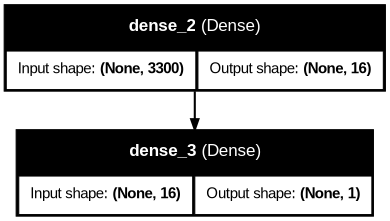

In [ ]:
plot_model(  # Diagrama visual de la arquitectura.
    modelo_tf, show_shapes=True, show_layer_names=True, dpi=75
)

In [ ]:
entradas = X_train_tf.shape[1]  # Cantidad real de predictores tras One-Hot.
parametros_esperados = (entradas * 16 + 16) + (16 * 1 + 1)  # Pesos + sesgos.
print("Parámetros esperados:", parametros_esperados)
print("Parámetros reportados por Keras:", modelo_tf.count_params())

Parámetros esperados: 52833
Parámetros reportados por Keras: 52833


###Compilar la red
`Adam` actualiza los pesos; `mse` (error cuadrático medio) penaliza especialmente los errores grandes; `mae` informa el error absoluto promedio. **Ambas métricas están en escala del objetivo transformado** durante el entrenamiento.

In [ ]:
modelo_tf.compile(  # Elegimos cómo aprende la red.
    optimizer="adam",  # Método de optimización.
    loss="mse",  # Función de pérdida para regresión.
    metrics=["mae"]  # Otra métrica de monitoreo.
)
print("Modelo compilado correctamente")

Modelo compilado correctamente


###Entrenar por épocas
Cada **época** recorre los datos de entrenamiento. `validation_split=0.20` reserva una parte de *train* para validar; los registros de `test` permanecen intactos. `verbose=1` muestra el aprendizaje por época.

In [ ]:
historial_tf = modelo_tf.fit(  # Entrenamiento de la red TensorFlow.
    X_train_tf, y_train_tf,  # Entradas y precios escalados de train.
    epochs=60,  # Número de pasadas por el conjunto.
    batch_size=32,  # Casas procesados antes de actualizar pesos.
    validation_split=0.20,  # Validación tomada solo de train.
    shuffle=True,  # Mezcla las observaciones en cada época.
    verbose=1  # Muestra el avance y las métricas por época.
)

Epoch 1/60
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.6929 - mae: 0.6432 - val_loss: 0.5651 - val_mae: 0.5271
Epoch 2/60
79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.3783 - mae: 0.4185 - val_loss: 0.4289 - val_mae: 0.4149
Epoch 3/60
79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.2853 - mae: 0.3385 - val_loss: 0.3935 - val_mae: 0.3906
Epoch 4/60
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.2387 - mae: 0.2926 - val_loss: 0.3788 - val_mae: 0.3818
Epoch 5/60
79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.2042 - mae: 0.2538 - val_loss: 0.3711 - val_mae: 0.3774
Epoch 6/60
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.1757 - mae: 0.2190 - val_loss: 0.3686 - val_mae: 0.3760
Epoch 7/60
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.1512 - mae: 0.1878 - val_loss: 0.3670 - val_mae: 0.3758
Epoch 8/60
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.1299 - mae: 0.1605 - val_loss: 0.3688 - val_mae: 0.3794
Epoch 9/60
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.1115 - mae: 

###Visualizar el aprendizaje
Comparamos entrenamiento y validación para detectar divergencias. Una pérdida de entrenamiento más baja **no garantiza** mejores predicciones en casas no vistos.

In [ ]:
curvas_tf = pd.DataFrame(historial_tf.history)  # Historial completo de Keras.
curvas_tf["Epoca"] = range(1, len(curvas_tf) + 1)  # Identifica cada época.
display(curvas_tf.head())  # Primeras cinco épocas.

,loss,mae,val_loss,val_mae,Epoca
0,0.69,0.64,0.57,0.53,1
1,0.38,0.42,0.43,0.41,2
2,0.29,0.34,0.39,0.39,3
3,0.24,0.29,0.38,0.38,4
4,0.20,0.25,0.37,0.38,5


In [ ]:
px.line(  # MSE en train y en validación, en escala estandarizada.
    curvas_tf, x="Epoca", y=["loss", "val_loss"],
    labels={"value": "Pérdida MSE", "variable": "Conjunto"},
    title="TensorFlow: evolución del error cuadrático medio"
).show()

In [ ]:
px.line(  # MAE de entrenamiento y validación, en escala transformada.
    curvas_tf, x="Epoca", y=["mae", "val_mae"],
    labels={"value": "MAE estandarizado", "variable": "Conjunto"},
    title="TensorFlow: evolución del error absoluto medio"
).show()

###Predecir y recuperar los precios
`predict()` devuelve números en la **escala estandarizada**. Con `inverse_transform()` recuperamos la unidad de `price` utilizando exclusivamente el escalador aprendido de entrenamiento.

In [ ]:
pred_tf_escalado = modelo_tf.predict(  # Predice los vehículos de prueba.
    X_test_tf, verbose=0
)
pred_tf = escalador_y.inverse_transform(  # Invierte el escalado del objetivo.
    pred_tf_escalado
).ravel()  # Vector de precios estimados

print("Primeros precios estimados :", pred_tf[:5].round(2))

Primeros precios estimados : [738525.75 243134.19 574266.4  430883.53 736328.25]


### Evaluamos las métricas MAE, RMSE, R2
En MAE y RMSE, menor es mejor; en R², mayor es mejor.

In [ ]:
metricas_tf = evaluar(y_test, pred_tf)  # Compara precio real y estimado.
print("Resultados TensorFlow/Keras:", metricas_tf)

Resultados TensorFlow/Keras: {'MAE': 89995.90292137324, 'RMSE': np.float64(135117.15918993665), 'R2': 0.631186566796718}


In [ ]:
comparacion["TensorFlow/Keras"] = pred_tf  # Añade predicción al mismo conjunto de prueba.
comparacion["Error_TF"] = comparacion["Real"] - comparacion["TensorFlow/Keras"]  # Residuo.
display(comparacion[["Real", "TensorFlow/Keras", "Error_TF"]].head(20).round(2))

,Real,TensorFlow/Keras,Error_TF
3670,530000.00,738525,-208525.75
486,243000.00,243134,-134.17
4070,362750.00,574266,-211516.38
3802,625000.00,430883,194116.47
2199,1010000.00,736328,273671.75
4057,309000.00,418275,-109275.84
690,926300.00,660902,265397.12
874,375000.00,377559,-2559.78
4033,300000.00,535331,-235331.25
3945,0.00,946151,-946151.00


In [ ]:
fig_tf = px.scatter(  # Diagnóstico: precio real frente a predicho.
    comparacion, x="Real", y="TensorFlow/Keras",
    labels={"Real": "Precio real ", "TensorFlow/Keras": "Precio estimado "},
    title="TensorFlow/Keras: precio real vs. estimado"
)
fig_tf.add_shape(  # Línea ideal: predicción igual al valor real.
    type="line", x0=comparacion["Real"].min(), y0=comparacion["Real"].min(),
    x1=comparacion["Real"].max(), y1=comparacion["Real"].max(),
    line=dict(dash="dash")
)
fig_tf.show()

#7. Modelo con PyTorch
Repetimos el enfoque celda por celda: importar, preparar tensores, construir arquitectura, definir criterio y optimizador, recorrer épocas, visualizar pérdida, predecir y evaluar.

Arquitectura: entradas → 16 neuronas ReLU → 8 neuronas ReLU → 1 salida lineal. La salida predice el precio transformado; no se usa sigmoide. PyTorch calculará explícitamente gradientes y actualizará los parámetros.

In [ ]:
import torch  # Librería para operar con tensores y entrenar redes.
import torch.nn as nn  # Capas, activaciones y funciones de pérdida.
torch.manual_seed(42)  # Fija semilla para reproducibilidad.

###Preparar tensores para Pytorch
Convertimos la matriz transformada a `torch.float32`. La respuesta tiene forma `(n, 1)` para que coincida con la neurona de salida. **No repetimos** el ajuste de codificación ni usamos información de prueba para entrenar.


In [ ]:
X_train_pt = torch.tensor(X_train_listo, dtype=torch.float32)  # Entradas de entrenamiento.
X_test_pt = torch.tensor(X_test_listo, dtype=torch.float32)  # Entradas de prueba.
y_train_pt = torch.tensor(y_train_tf, dtype=torch.float32)  # Precio ya escalado: n filas x 1.

print("X_train:", X_train_pt.shape, "| y_train:", y_train_pt.shape)
print("Dos casas transformados:", X_train_pt[:2])

X_train: torch.Size([3140, 3300]) | y_train: torch.Size([3140, 1])
Dos casas transformados: tensor([[-1.5316,  0.5410,  0.1380,  ...,  0.0000,  0.0000,  1.0000],
        [-0.4153,  0.5410,  1.0750,  ...,  0.0000,  0.0000,  1.0000]])


###Construir la arquitectura
`Linear` aprende pesos y sesgos; `ReLU` aporta no linealidad; la última capa `Linear(8, 1)` produce un valor continuo. Usamos `nn.Sequential`, para evitar clases personalizadas y hacer visible cada capa.

In [ ]:
modelo_pt = nn.Sequential(  # Capas organizadas secuencialmente.
    nn.Linear(X_train_pt.shape[1], 16),  # Predictores transformados → 16 neuronas.
    nn.ReLU(),  # Primera activación no lineal.
    nn.Linear(16, 8),  # Segunda capa oculta: 16 → 8 neuronas.
    nn.ReLU(),  # Segunda activación no lineal.
    nn.Linear(8, 1)  # Salida: precio escalado, sin activación.
)
print(modelo_pt)  # Inspecciona visualmente las capas.

Sequential(
  (0): Linear(in_features=3300, out_features=16, bias=True)
  (1): ReLU()
  (2): Linear(in_features=16, out_features=8, bias=True)
  (3): ReLU()
  (4): Linear(in_features=8, out_features=1, bias=True)
)


In [ ]:
parametros_pt = sum(  # Cuenta todos los pesos y sesgos entrenables.
    p.numel() for p in modelo_pt.parameters() if p.requires_grad
)
print("Número de parámetros PyTorch:", parametros_pt)

Número de parámetros PyTorch: 52961


###Elegir la pérdida y el optimizador
`MSELoss` es adecuado para un objetivo numérico. `Adam` actualiza los parámetros después de calcular los gradientes. Aquí **no** aplicamos `BCEWithLogitsLoss`, porque esa pérdida pertenece a clasificación binaria.

In [ ]:
criterio = nn.MSELoss()  # Error cuadrático medio para regresión.
optimizador = torch.optim.Adam(  # Algoritmo para modificar pesos y sesgos.
    modelo_pt.parameters(), lr=0.005  # Tasa de aprendizaje.
)
perdidas_pt = []  # Guardaremos el error de cada época para representarlo.

###Entrenar paso a paso por épocas
En cada época: (1) activar modo entrenamiento, (2) borrar gradientes anteriores, (3) predecir, (4) medir el error, (5) calcular nuevos gradientes, (6) actualizar pesos, (7) registrar y mostrar pérdida. Esta estructura permite explicar línea por línea qué hace PyTorch.

In [ ]:
for epoca in range(80):  # 80 recorridos completos del conjunto de entrenamiento.
    modelo_pt.train()  # Activa el comportamiento de entrenamiento.
    optimizador.zero_grad()  # Limpia los gradientes de la época anterior.
    salida_pt = modelo_pt(X_train_pt)  # Calcula precios escalados estimados.
    perdida_pt = criterio(salida_pt, y_train_pt)  # Calcula el error MSE.
    perdida_pt.backward()  # Obtiene derivadas del error respecto a los pesos.
    optimizador.step()  # Actualiza los parámetros para reducir el error.
    perdidas_pt.append(perdida_pt.item())  # Almacena el MSE de esta época.
    print(f"Época {epoca + 1:02d}/80 | pérdida MSE: {perdida_pt.item():.4f}")

Época 01/80 | pérdida MSE: 1.0072
Época 02/80 | pérdida MSE: 0.9921
Época 03/80 | pérdida MSE: 0.9786
Época 04/80 | pérdida MSE: 0.9634
Época 05/80 | pérdida MSE: 0.9450
Época 06/80 | pérdida MSE: 0.9241
Época 07/80 | pérdida MSE: 0.9010
Época 08/80 | pérdida MSE: 0.8762
Época 09/80 | pérdida MSE: 0.8497
Época 10/80 | pérdida MSE: 0.8210
Época 11/80 | pérdida MSE: 0.7899
Época 12/80 | pérdida MSE: 0.7567
Época 13/80 | pérdida MSE: 0.7216
Época 14/80 | pérdida MSE: 0.6847
Época 15/80 | pérdida MSE: 0.6467
Época 16/80 | pérdida MSE: 0.6081
Época 17/80 | pérdida MSE: 0.5696
Época 18/80 | pérdida MSE: 0.5319
Época 19/80 | pérdida MSE: 0.4957
Época 20/80 | pérdida MSE: 0.4615
Época 21/80 | pérdida MSE: 0.4299
Época 22/80 | pérdida MSE: 0.4011
Época 23/80 | pérdida MSE: 0.3755
Época 24/80 | pérdida MSE: 0.3529
Época 25/80 | pérdida MSE: 0.3332
Época 26/80 | pérdida MSE: 0.3162
Época 27/80 | pérdida MSE: 0.3018
Época 28/80 | pérdida MSE: 0.2899
Época 29/80 | pérdida MSE: 0.2803
Época 30/80 | 

###Visualizar la evolución del error
Una curva decreciente confirma que el optimizador reduce el error de entrenamiento, **pero no comprueba generalización**. La evaluación sobre `X_test` será independiente.

In [ ]:
px.line(  # Gráfico interactivo de la pérdida por época.
    x=range(1, len(perdidas_pt) + 1), y=perdidas_pt,
    labels={"x": "Época", "y": "MSE estandarizado"},
    title="PyTorch: evolución de la pérdida de entrenamiento"
).show()

### Realizar predicciones
`eval()` coloca la red en modo evaluación; `torch.no_grad()` evita calcular derivadas. Las salidas se convierten a NumPy y se **desestandarizan** para recuperar la unidad del precio.

In [ ]:
modelo_pt.eval()  # Cambia al modo evaluación.
with torch.no_grad():  # No es necesario calcular gradientes en inferencia.
    pred_pt_escalado = modelo_pt(X_test_pt).numpy()  # Salidas numéricas transformadas.

pred_pt = escalador_y.inverse_transform(  # Recupera precios en USD.
    pred_pt_escalado
).ravel()
print("Primeros precios estimados :", pred_pt[:5].round(2))

Primeros precios estimados : [760530.   288294.9  495831.28 437907.12 753814.5 ]


###Evaluar PyTorch
Comparamos sobre las **mismas casas de prueba** que los demás modelos. Los errores deben interpretarse en unidades monetarias, no en la escala usada internamente al entrenar.

In [ ]:
metricas_pt = evaluar(y_test, pred_pt)  # MAE, RMSE y R² sobre precios reales.
print("Resultados PyTorch:", metricas_pt)

Resultados PyTorch: {'MAE': 83680.82894299108, 'RMSE': np.float64(129325.90707953417), 'R2': 0.6621244342995574}


In [ ]:
comparacion["PyTorch"] = pred_pt  # Agrega las predicciones al cuadro conjunto.
comparacion["Error_PT"] = comparacion["Real"] - comparacion["PyTorch"]  # Residuo.
display(comparacion[["Real", "PyTorch", "Error_PT"]].head(20).round(2))

,Real,PyTorch,Error_PT
3670,530000.00,760530,-230530.00
486,243000.00,288294,-45294.91
4070,362750.00,495831,-133081.28
3802,625000.00,437907,187092.88
2199,1010000.00,753814,256185.50
4057,309000.00,430199,-121199.19
690,926300.00,617986,308314.00
874,375000.00,404360,-29360.62
4033,300000.00,485654,-185654.28
3945,0.00,850393,-850393.12


In [ ]:
fig_pt = px.scatter(  # Valores observados vs. precios predichos.
    comparacion, x="Real", y="PyTorch",
    labels={"Real": "Precio real ", "PyTorch": "Precio estimado "},
    title="PyTorch: precio real frente a precio estimado"
)
fig_pt.add_shape(  # Línea de predicción perfecta.
    type="line", x0=comparacion["Real"].min(), y0=comparacion["Real"].min(),
    x1=comparacion["Real"].max(), y1=comparacion["Real"].max(),
    line=dict(dash="dash")
)
fig_pt.show()

#8. Comparación final de modelos
Los cinco algoritmos predicen `price` usando **exactamente el mismo conjunto de prueba**. Usamos **MAE (USD)**, **RMSE (USD)** y **R²**. Una arquitectura más profunda no necesariamente supera a un modelo de árboles.

In [ ]:
predicciones = {  # Reunimos todos los valores predichos para comparar.
    "Regresión lineal": pred_lineal,
    "Árbol de regresión": pred_arbol,
    "Random Forest": pred_rf,
    "TensorFlow/Keras": pred_tf,
    "PyTorch": pred_pt
}
resultados = []  # Guarda una fila de métricas por modelo.
for nombre, pred in predicciones.items():  # Evalúa a todos con la misma fórmula.
    resultados.append({"Modelo": nombre, **evaluar(y_test, pred)})
metricas = pd.DataFrame(resultados)  # Tabla comparativa.
display(metricas.sort_values("RMSE").round(3))

,Modelo,MAE,RMSE,R2
4,PyTorch,83680.83,129325.91,0.66
3,TensorFlow/Keras,89995.90,135117.16,0.63
2,Random Forest,86406.31,136941.57,0.62
0,Regresión lineal,100225.00,153966.26,0.52
1,Árbol de regresión,115042.89,162634.46,0.47


In [ ]:
px.bar(  # Menor RMSE indica menor error penalizando errores grandes.
    metricas.sort_values("RMSE"), x="Modelo", y="RMSE",
    title="Regresión: comparación del RMSE"
).show()

In [ ]:
px.bar(  # Menor MAE corresponde a menor desviación absoluta media.
    metricas.sort_values("MAE"), x="Modelo", y="MAE",
    title="Regresión: comparación del MAE"
).show()

In [ ]:
px.bar(  # R² mide ajuste relativo respecto a una predicción constante de la media.
    metricas.sort_values("R2", ascending=False), x="Modelo", y="R2",
    title="Regresión: comparación de R²"
).show()

### Comparación casa por casa
Cada fila es una casa de X_test. El precio real puede compararse horizontalmente con las cinco predicciones.

In [ ]:
# Crear tabla comparativa con valores reales.
comparacion_final = pd.DataFrame({
    "Real": np.asarray(y_test).ravel()
})

# Incorporar las predicciones de cada modelo.
for nombre, valores in predicciones.items():
    comparacion_final[nombre] = np.asarray(valores).ravel()

# Visualizar las primeras 30 casas.
display(comparacion_final.head(30).round(2))


,Real,Regresión lineal,Árbol de regresión,Random Forest,TensorFlow/Keras,PyTorch
0,530000.00,758612.98,798111.11,901621.30,738525,760530
1,243000.00,173249.88,183642.86,344266.02,243134,288294
2,362750.00,655208.73,424286.24,494753.88,574266,495831
3,625000.00,500438.01,719187.66,496219.40,430883,437907
4,1010000.00,861807.38,611500.37,631118.62,736328,753814
5,309000.00,314922.89,551207.48,422773.63,418275,430199
6,926300.00,615041.53,594078.83,720390.63,660902,617986
7,375000.00,320309.90,504250.01,415529.86,377559,404360
8,300000.00,537450.07,551207.48,470186.13,535331,485654
9,0.00,781324.93,807870.43,892365.88,946151,850393


###Mapa de calor de errores absolutos
En regresión, el equivalente es mostrar **qué tan lejos** está cada predicción del precio real. Aquí visualizamos las primeras 30 casas para que las anotaciones sigan siendo legibles.

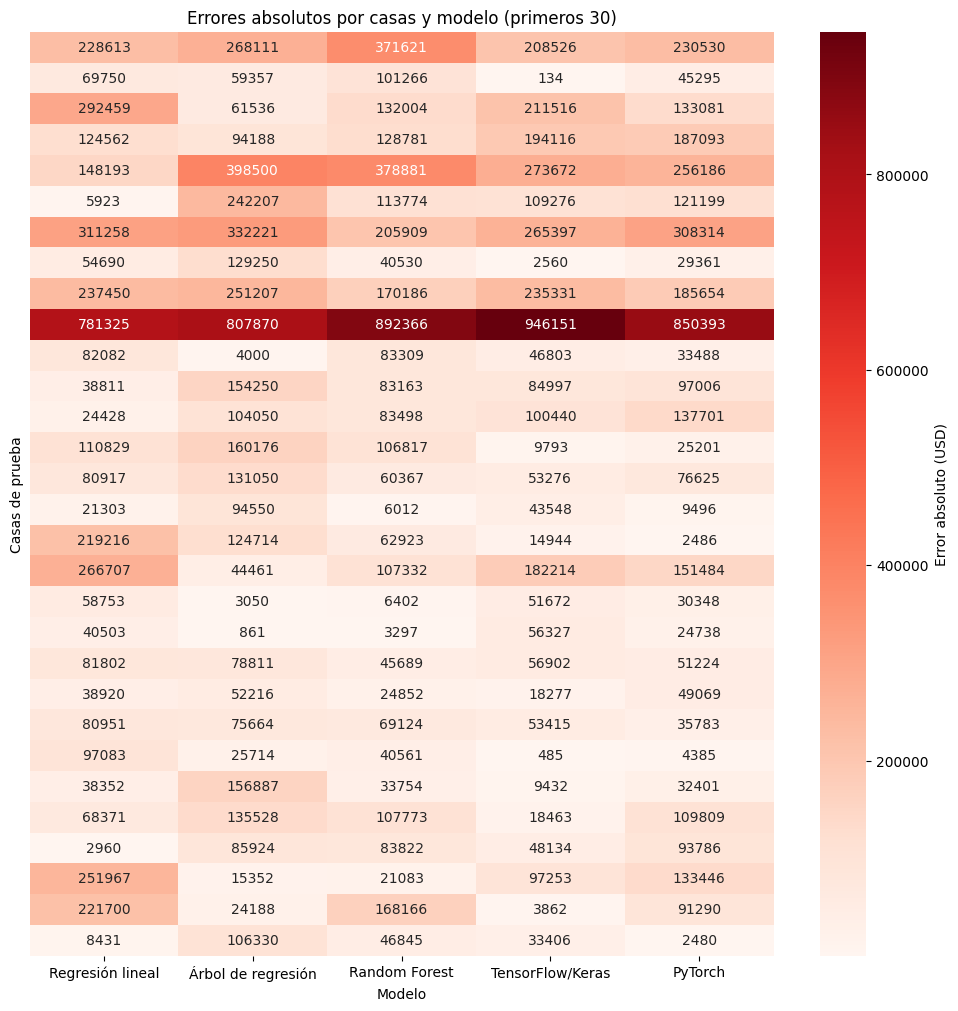

In [ ]:
errores_absolutos = pd.DataFrame({  # Distancia absoluta entre real y estimado.
    nombre: np.abs(y_test.to_numpy() - pred)
    for nombre, pred in predicciones.items()
}, index=y_test.index)

plt.figure(figsize=(12, 12))  # Ancho para los cinco regresores.
sns.heatmap(  # Cada color representa la magnitud del error en USD.
    errores_absolutos.head(30), cmap="Reds", annot=True, fmt=".0f",
    cbar_kws={"label": "Error absoluto (USD)"}, yticklabels=False
)
plt.title("Errores absolutos por casas y modelo (primeros 30)")
plt.xlabel("Modelo")
plt.ylabel("Casas de prueba")
plt.show()

###Distribución de resíduos
El residuo es **precio real − precio estimado**. Un residuo positivo significa que el modelo subestimó el precio; uno negativo significa que lo sobreestimó.

In [ ]:
residuos = pd.DataFrame({  # Calcula residuos en USD para cada modelo.
    nombre: y_test.to_numpy() - pred
    for nombre, pred in predicciones.items()
})
px.box(  # Compara dispersión y valores extremos de los residuos.
    residuos, points="outliers", title="Distribución de residuos de los cinco regresores (USD)"
).show()

#**REFLEXIÓN FINAL**
Al analizar los resultados de los modelos: Regresión Lineal, Árbol de Regresión,	Random Forest,	TensorFlow/Keras y PyTorch puedo observar que R2 de PyTorch es el valor mas alto en los modelos, aúnque no se aproxima como una predicción aceptable (superior al 80%), además el precio estimado es algo distante del precio real.